# abINS and Python

The almost-isotropic powder-averaged incoherent approximation is implemented in Mantid, but is being  rewritten as a standalone "abinslib" library for access in other ways; web interface, automated workflows, AI coding tools, ...

Here we will use the euphonic-abinslib-resins stack to dive a bit deeper into what happens in the TOSCA simulation we performed in part 01.

## Import data and explore atom-projected DOS

Euphonic is used to import out MLIP force constants for ethanol and sample to a dense phonon DOS. This time we use the eigenvectors to project the DOS onto contributions from each atom.

In [37]:
from euphonic import ForceConstants, Quantity
from euphonic.plot import plot_1d, plot_1d_to_axis
from euphonic.util import mp_grid

import numpy as np

In [10]:
fc = ForceConstants.from_phonopy(summary_name="janus_results/ethanol-opt-phonopy.yml", fc_name="janus_results/ethanol-opt-force_constants.hdf5")

modes = fc.calculate_qpoint_phonon_modes(mp_grid((8, 8, 8)))

Force constants not found in janus_results/ethanol-opt-phonopy.yml, attempting to read from janus_results/ethanol-opt-force_constants.hdf5


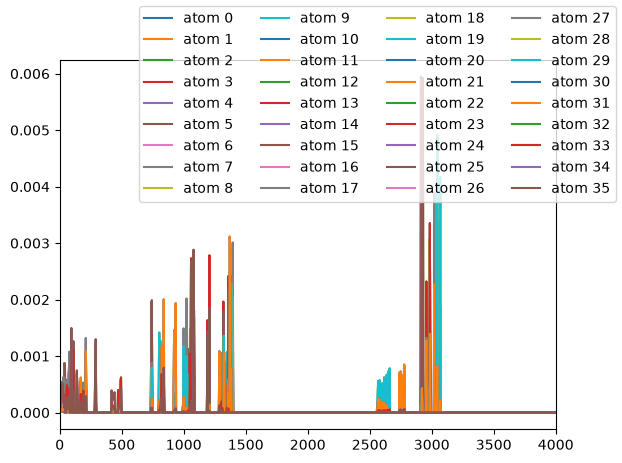

In [29]:
bins = Quantity(np.linspace(0, 4000, 1000), '1/cm')
pdos = modes.calculate_pdos(bins)
plt = plot_1d(pdos, labels=[f'atom {m["index"]}' for m in pdos.iter_metadata()])

plt.axes[0].get_legend().remove()  # single-column doesn't look good
plt.legend(ncol=4)

That isn't very easy to interpret! Let's group the atoms by their chemical element, add some broadening, and add a line representing the total DOS.

Text(0, 0.5, 'Density of states')

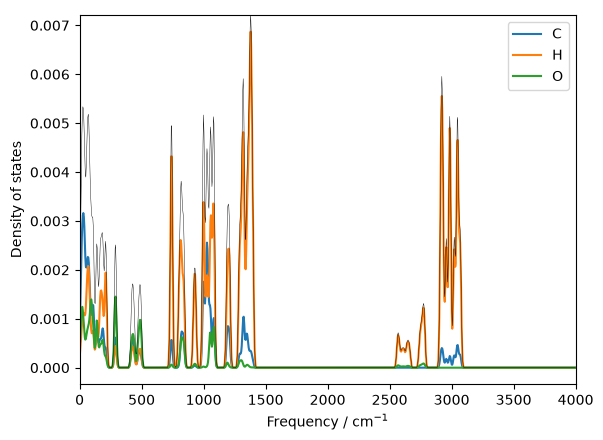

In [41]:
grouped_pdos = pdos.group_by('species').broaden(Quantity(20, '1/cm'))
total_dos = grouped_pdos.sum()

plt = plot_1d(grouped_pdos, labels=[f'{m["species"]}' for m in grouped_pdos.iter_metadata()])
ax = plt.axes[0]

plot_1d_to_axis(total_dos, ax, color='k', linewidth=0.3)
ax.set_xlabel('Frequency / cm$^{-1}$')
ax.set_ylabel('Density of states')

<div style="background-color:#fdf2e4;border-left:5px solid #c05621;border-radius:4px;padding:0.8em 1.2em;margin:0.6em 0;color:#1b1b1b">

**Questions**

What trends can we see here? Are they physically reasonable?

What units should the y-axis have?

What is the area under the total DOS?
</div>

## Neutron-weighted DOS

A simplistic "neutron-weighted" DOS can be created by multiplying each contribution by its neutron cross-section.

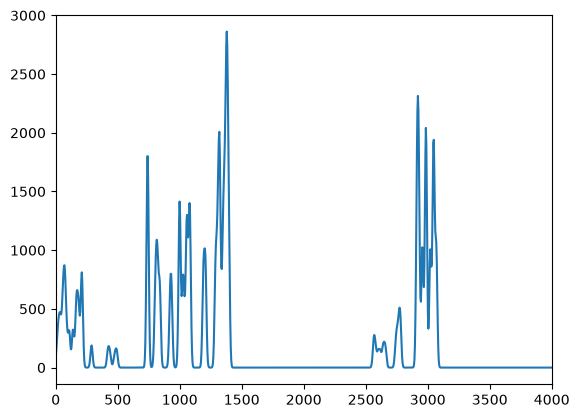

In [45]:
neutron_dos = modes.calculate_pdos(bins, weighting="coherent-plus-incoherent").sum().broaden(Quantity(20, '1/cm'))
plt = plot_1d(neutron_dos)

<div style="background-color:#fdf2e4;border-left:5px solid #c05621;border-radius:4px;padding:0.8em 1.2em;margin:0.6em 0;color:#1b1b1b">

**Questions**

Which INS instrument does this simulation correspond to?

What do we learn from such a plot?
</div>

## Atomic displacements

In the harmonic approximation, the dynamical structure contribution of atom $j$ and creation of phonon mode $\nu$ in quantum order $n$

$$S(\mathbf{q}, \omega_nu)_n = \frac{(\mathbf{q}\cdot\mathbf{u}_{\nu, j})^{2n}}{n!} \exp \left[ - \left(\mathbf{q} \sum_{\nu}{\mathbf{u}_{\nu, j}} \right)^2 \right]$$

A more physical simulation accounts for the thermal occupation of phonon modes, the displacement vectors $\mathbf{u}$ are hiding Bose occupation terms $\left<n+1\right>$ and $\left<2n+1\right>$ for the order-dependent and Debye-Waller terms respectively. Note this $n$ for Bose occupation is unrelated to the quantum order $n$. (For the "negative" spectrum of energy transferred from the system to incident neutrons, the $\left<n+1\right>$ is replaced by $\left<n\right>$.)

<div style="background-color:#fdf2e4;border-left:5px solid #c05621;border-radius:4px;padding:0.8em 1.2em;margin:0.6em 0;color:#1b1b1b">

**Questions**

- In energy *emission*, what happens to the $\mathbf{q}\cdot\mathbf{u}$ term as temperature goes to zero? Why?
- (Harder!) In energy *absorption*, what happens to this term as temperature increases? Why?
</div>

In abINS and similar approaches, the displacements are represented as **B**, a set of $3 \times 3$ tensors per atom and mode, and **A**, the sum over modes used in Debye–Waller exponent. This term is also known is crystallograph as "atomic displacement parameters" (ADP).

The Python class representing **B** is Displacements; this allows different Bose weighting to be selected and summation to a Quantity array representing **A**.

In [100]:
from abinslib.displacements import Displacements
from abinslib.util import calculate_indirect_q2, apply_weights
from abinslib.almost_isotropic_incoherent import (
    calculate_almost_isotropic_incoherent_spectra,
    mantid_like_combination_spectra,
)

# Calculate on a smaller q-point mesh than DOS this time.
q_mesh = (3, 3, 3)
temperature = Quantity(10, 'kelvin')
modes = fc.calculate_qpoint_phonon_modes(mp_grid(q_mesh))
mode_displacements = Displacements.from_modes(modes, temperature=temperature)
atomic_displacements = mode_displacements.to_atomic_displacements()

Note that modes with zero or negative frequency would nominally have infinite displacement; these are set to displacement zero to avoid an unphysical contribution from translational motion of the lattice.

In [101]:
QPT_INDEX = 13

print(f"Q-point {QPT_INDEX}: {modes.qpts[QPT_INDEX]}")
print("\nBottom six frequencies")
print(modes.frequencies[QPT_INDEX][:6])
print("\nCorresponding displacements")
print(mode_displacements.n_plus_one[QPT_INDEX, 0])

Q-point 13: [0. 0. 0.]

Bottom six frequencies
[-0.7797134324404122 -0.6490251842075891 -0.4590835262139349 1.788033171340229 2.6109074077053154 3.5469731128807718] millielectron_volt

Corresponding displacements
[[[0.0 0.0 0.0]  [0.0 0.0 0.0]  [0.0 0.0 0.0]] [[0.0 0.0 0.0]  [0.0 0.0 0.0]  [0.0 0.0 0.0]] [[0.0 0.0 0.0]  [0.0 0.0 0.0]  [0.0 0.0 0.0]] [[0.0 0.0 0.0]  [0.0 0.0 0.0]  [0.0 0.0 0.0]] [[0.0 0.0 0.0]  [0.0 0.0 0.0]  [0.0 0.0 0.0]] [[0.0 0.0 0.0]  [0.0 0.0 0.0]  [0.0 0.0 0.0]] [[0.0 0.0 0.0]  [0.0 0.0 0.0]  [0.0 0.0 0.0]] [[0.0 0.0 0.0]  [0.0 0.0 0.0]  [0.0 0.0 0.0]] [[0.0 0.0 0.0]  [0.0 0.0 0.0]  [0.0 0.0 0.0]] [[0.0 0.0 0.0]  [0.0 0.0 0.0]  [0.0 0.0 0.0]] [[0.0 0.0 0.0]  [0.0 0.0 0.0]  [0.0 0.0 0.0]] [[0.0 0.0 0.0]  [0.0 0.0 0.0]  [0.0 0.0 0.0]] [[0.0 0.0 0.0]  [0.0 0.0 0.0]  [0.0 0.0 0.0]] [[0.0 0.0 0.0]  [0.0 0.0 0.0]  [0.0 0.0 0.0]] [[0.0 0.0 0.0]  [0.0 0.0 0.0]  [0.0 0.0 0.0]] [[0.0 0.0 0.0]  [0.0 0.0 0.0]  [0.0 0.0 0.0]] [[0.0 0.0 0.0]  [0.0 0.0 0.0]  [0.0 0.0 0.0]] [[0.

## Energy-Q relations

In the "almost-isotropic powder-averaging incoherent approximation" of abINS, $Q^2$ values are inserted based on instrument geometry and decoupled from the original phonon DOS.

On TOSCA the final energy $E_f$ fixed by the analyzer crystals and the incident energy $E_i = E_f + \hbar\omega$ follows the energy transfer: the momentum transfer at scattering angle $2\theta$ is
$Q^2 = \frac{2m_n}{\hbar^2}\left(E_i + E_f - 2\sqrt{E_i E_f}\cos 2\theta\right)$.

TOSCA has detector banks in forward and back scattering: here we use the backscattering bank at 135°.
$Q^2$ grows nearly linearly with energy transfer, which is what makes the Debye-Waller factor and the multi-phonon terms important at high energies.

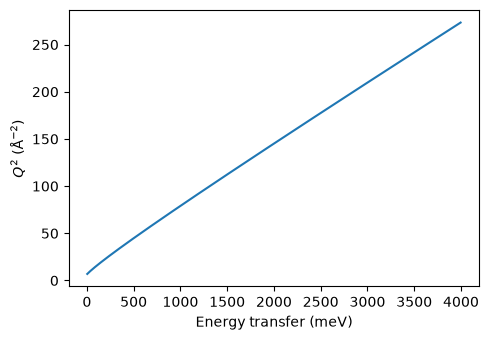

In [102]:
import matplotlib.pyplot as plt
DETECTOR_ANGLE = 135 # degree
FINAL_ENERGY = 3.97 # meV
BIN_RANGE = 4000 # 1/cm
N_BINS = 500

angle = DETECTOR_ANGLE * np.pi / 180
e_final = Quantity(FINAL_ENERGY, 'meV')
bins = Quantity(np.linspace(0, BIN_RANGE, N_BINS), '1/cm')
bin_centres = (bins[1:] + bins[:-1]) / 2

# Calculate on mode frequencies as well as on bins; this will be used for an optimisation later
mode_q2 = calculate_indirect_q2(modes.frequencies, angle=angle, final_energy=e_final)
binned_q2 = calculate_indirect_q2(bin_centres, angle=angle, final_energy=e_final)

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(bin_centres.magnitude, binned_q2.to('angstrom^-2').magnitude)
ax.set_xlabel('Energy transfer (meV)')
ax.set_ylabel('$Q^2$ (Å$^{-2}$)')
fig.tight_layout()
plt.show()

## Intensity calculation

In a fully-isotropic powder approximation we would simply replace $(\mathbf{q}\cdot\mathbf{u})^2$ with $|\mathbf{q}|^2 \frac{\mathrm{tr}(\mathbf{B})}{3}$, i.e. take an average over the diagonal terms.

The almost-isotropic approximation used here is slightly more elaborate, but still works as an approximate analytic spherical average over the incpherent scattering of harmonic phonon modes.

As an optimisation, the second-order term applies $|\mathbf{q}|^2$ scaling to the _bins_ after an initial calculation step: we provide these as input to the appropriate abinslib function. The orders are brought together into a Spectrum1DCollection object and scattering cross-sections applied to simulate the TOSCA backscattering intensities.

In [103]:
%%capture
fundamentals = calculate_almost_isotropic_incoherent_spectra(
    modes=modes,
    mode_displacements=mode_displacements,
    atomic_displacements=atomic_displacements,
    nominal_q2=mode_q2,
    bins=bins,
)
second_order = mantid_like_combination_spectra(
    modes, mode_displacements, atomic_displacements, binned_q2, bins,
)
spectra = apply_weights(fundamentals + second_order, key='scattering_cross_section')

The collection can be summed over any label in its metadata. Grouping by element shows which atoms carry the intensity, grouping by quantum order how the two-phonon terms create a broader base spectrum.

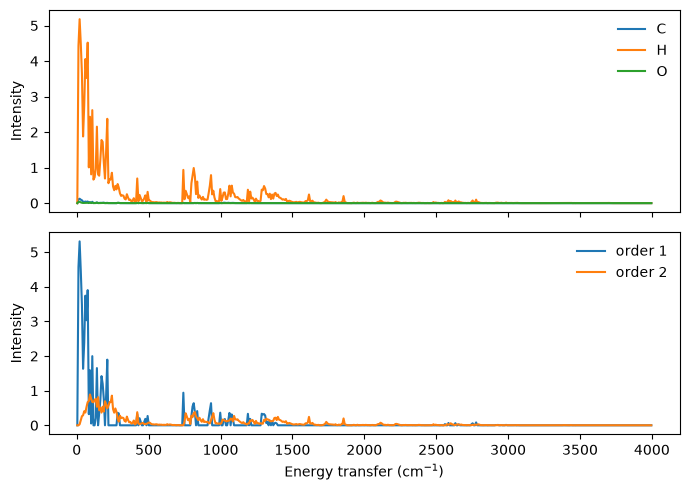

In [104]:
fig, axes = plt.subplots(2, 1, figsize=(7, 5), sharex=True)
for spectrum in spectra.group_by('atom_symbol'):
    axes[0].plot(spectrum.get_bin_centres().magnitude, spectrum.y_data.magnitude, label=spectrum.metadata['atom_symbol'])
for spectrum in spectra.group_by('quantum_order'):
    axes[1].plot(spectrum.get_bin_centres().magnitude, spectrum.y_data.magnitude, label=f"order {spectrum.metadata['quantum_order']}")
for ax in axes:
    ax.legend(frameon=False)
    ax.set_ylabel('Intensity')
axes[1].set_xlabel('Energy transfer (cm$^{-1}$)')
fig.tight_layout()
plt.show()

## Instrument resolution

The energy resolution of TOSCA is _roughly_ a constant fraction of energy transfer, yielding broader peaks at higher frequencies. The [resins](https://github.com/pace-neutrons/resins) library provides resolution functions of various instruments, and is used here to apply an established function for TOSCA. `resins` uses meV consistently, so the Quantity objects from euphonic/abinslib are cast to/from this preferred unit as appropriate.

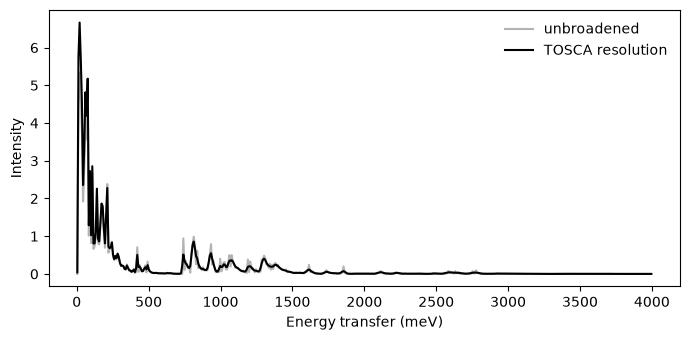

In [107]:
from resins import Instrument

energy_mev = total.get_bin_centres().to('meV').magnitude
energy_cm = total.get_bin_centres().to('1/cm').magnitude
bin_width = energy_mev[1] - energy_mev[0]

total = spectra.sum()
tosca = Instrument.from_default('TOSCA')
resolution = tosca.get_resolution_function('AbINS_v1')
broadened = resolution.broaden(points=energy_mev[:, None], data=total.y_data.magnitude, mesh=energy_mev) * bin_width

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(energy_cm, total.y_data.magnitude, color='0.7', label='unbroadened')
ax.plot(energy_cm, broadened, color='k', label='TOSCA resolution')
ax.set_xlabel('Energy transfer (meV)')
ax.set_ylabel('Intensity')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

<div style="background-color:#fdf2e4;border-left:5px solid #c05621;border-radius:4px;padding:0.8em 1.2em;margin:0.6em 0;color:#1b1b1b">

**Questions**

- Why are these measurements made at low temperature?
- How well does this match experimental measurements?
- What steps could we take to improve the simulation?
</div>

## Further reading

isisneutronmuon.github.io/abins_lib